# Stage 3 - Semantic analysis (STTM + SBERT) on labelled controls

**Goal.** Test `SemanticNLPModel`: describe sessions as *text*, cluster them with a short-text topic model (GSDMM), a classic topic model (LDA) or sentence embeddings (SBERT), describe each cluster in words, and compare against Stage 2 on data whose true groups we know.

### Why each method was chosen (for the project documentation)

| Component | Choice | Why | Main limitation |
|---|---|---|---|
| Session -> text | **`SessionRenderer`**: symbols / words / natural, optional run-length encoding and last-n window | The only place where word meaning can enter; RLE and windows fight the dilution of mean pooling (Experiment 4 of the plan) | Tied to the token format (`action_category.path`); other logs need a template map |
| Topic model, short text | **GSDMM** (one topic per session) | Sessions are short texts; Qiang et al. (2022) recommend it; it is a clustering model, so no k-means on top | Chooses its own number of clusters (k is only an upper bound); slowest component (Python loop over sessions) |
| Topic model, baseline | **LDA** (scikit-learn) | Named in the plan (Bar-El et al.); the survey says short-text models beat it, so we check | Needs mixtures over several topics, which 3-6 events barely support |
| Terms | **unigrams + bigrams** (with `<START>`/`<END>`) | Bag-of-words models cannot see order; bigrams are the 2-grams of Stage 2 | Vocabulary grows with the event vocabulary squared |
| Embedding | **SBERT** `all-MiniLM-L6-v2` + spherical k-means | One vector per session (no pairwise BERT passes); k-means is linear in N and is the engine of Stage 2 | Pre-trained on natural sentences; mean pooling dilutes long sessions; 256-piece input limit (verify) |
| Describing | **c-TF-IDF terms + closest sessions** | Embedding clusters are otherwise unreadable | Terms describe, they do not prove, the cluster |
| Behaviour profile | **Stage 2 Markov profile on any labels** (`profile()`) | Same descriptors for every approach, so the comparison isolates the clustering | Circularity if the clusters were built from the same transitions |

### How to read this notebook
* **Controls say what a method CAN do; real data says what it DOES.** Everything here is synthetic with known groups.
* The encoder cell below tells which encoder produced the saved numbers. If it says *STAND-IN*, the embedding rows are a **lexical control** (a hashed bag of words, no meaning); re-run on a machine that can download SBERT for the real rows.

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent                      # v0.2/ root, so `journey_analyzer` imports from notebooks/
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from journey_analyzer import TransitionModel, SemanticNLPModel
from journey_analyzer.evaluation import adjusted_rand_index, cluster_purity
from journey_analyzer.semantic import (SessionRenderer, SBERTEncoder, HashingEncoder, make_terms)
from journey_analyzer.transitions import START, END
from journey_analyzer.visualization import plot_transition_matrix

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 90)

## 1. Which encoder produced these numbers?
SBERT needs to download `all-MiniLM-L6-v2` (about 90 MB) once. On a machine without internet, download the folder elsewhere and put its path in `SBERT_MODEL`.

If SBERT cannot be loaded, the notebook **does not stop and does not pretend**: it falls back to `HashingEncoder`, a deterministic bag of hashed words with the same 384 dimensions. That is not a language model, but it is a useful **control**: if SBERT does not beat it, pre-trained semantics added nothing. Every table labels which one was used.

In [2]:
USE_SBERT = True
SBERT_MODEL = "sentence-transformers/all-MiniLM-L6-v2"      # or a local folder

def make_encoder():
    if USE_SBERT:
        try:
            enc = SBERTEncoder(SBERT_MODEL); enc.load()
            return enc, "SBERT"
        except Exception as e:                                # no internet, no package, ...
            print("!! SBERT not available -> using the lexical STAND-IN.\n   reason:", str(e).splitlines()[0][:160])
    return SBERTEncoder(encoder=HashingEncoder(384)), "HashingEncoder (STAND-IN, no semantics)"

ENCODER, ENCODER_NAME = make_encoder()
print("encoder used for the 'embedding' rows:", ENCODER_NAME)

!! SBERT not available -> using the lexical STAND-IN.
   reason: SBERTEncoder needs sentence-transformers: pip install sentence-transformers (or inject an encoder, e.g. HashingEncoder()).
encoder used for the 'embedding' rows: HashingEncoder (STAND-IN, no semantics)


## 2. From a session to text: the rendering is a design variable
A language model sees a string, so the string decides what it can learn. The same session in five renderings:

In [3]:
demo = ["view_electronics.smartphone"] * 3 + ["cart_electronics.smartphone", "purchase_electronics.smartphone"]
renderers = {
    "symbols":                SessionRenderer("symbols"),
    "words":                  SessionRenderer("words"),
    "natural":                SessionRenderer("natural"),
    "natural + RLE":          SessionRenderer("natural", rle=True),
    "natural + RLE + last 2": SessionRenderer("natural", rle=True, window=2),
}
pd.Series({k: r.render(demo) for k, r in renderers.items()}, name="text the encoder sees").to_frame()

,text the encoder sees
symbols,view_electronics.smartphone view_electronics.smartphone view_electronics.smartphone ca...
words,"view electronics smartphone, view electronics smartphone, view electronics smartphone,..."
natural,"viewed electronics smartphone, viewed electronics smartphone, viewed electronics smart..."
natural + RLE,"viewed electronics smartphone x3, added electronics smartphone to cart, purchased elec..."
natural + RLE + last 2,"added electronics smartphone to cart, purchased electronics smartphone"


* `symbols` is the control: the exact tokens, nothing interpreted.
* `natural` turns `cart_...` into "added ... to cart", the kind of sentence SBERT was trained on.
* **RLE** keeps `view x3` from drowning the three events that matter. **The window** keeps only the end of the session, where the outcome is decided and where an input-length cut would otherwise remove it.
* Tokens without a known action (`login`, `page_view`) pass through as plain words; a numeric category (`view_2053013555631882655`) becomes "viewed item".

## 3. What the topic models see: terms, and why unigrams are order-blind
LDA and GSDMM only count terms. With single events as terms, a funnel and its reverse are the same document; bigram terms (the 2-grams of Stage 2, with boundaries) are what bring order in.

In [4]:
fwd = ["page_view", "click", "product_view", "add_to_cart", "purchase"]
rev = fwd[::-1]
show = pd.DataFrame({
    "unigram terms (forward)":  [sorted(make_terms(fwd, "unigram"))],
    "unigram terms (reverse)":  [sorted(make_terms(rev, "unigram"))],
    "same bag?":                [sorted(make_terms(fwd, "unigram")) == sorted(make_terms(rev, "unigram"))],
    "bigram terms in common":   [len(set(make_terms(fwd, "bigram")) & set(make_terms(rev, "bigram")))],
    "bigram terms (forward)":   [len(make_terms(fwd, "bigram"))],
}).T
show.columns = ["value"]; show

,value
unigram terms (forward),"[add_to_cart, click, page_view, product_view, purchase]"
unigram terms (reverse),"[add_to_cart, click, page_view, product_view, purchase]"
same bag?,True
bigram terms in common,0
bigram terms (forward),6


## 4. Control datasets (known groups)
Same generators as the Stage 2 notebook plus two new ones. All are seeded, and **the data seed and the clustering seed are different**, so a lucky data draw cannot also be a lucky initialisation.

| Control | Groups differ in | Favours |
|---|---|---|
| **K1 dynamics** | which events and what follows what (buyer / browser / bouncer Markov chains) | any method |
| **K2 order-only** | same events, opposite order (forward vs reversed funnel) | order-aware representations |
| **K5 two vocabularies** | K1, but half the sessions use synonyms (`login` -> `sign_in`, `purchase` -> `checkout_done`...) | methods that know word meaning |
| **K_window** | only the **last two events** (long common browsing prefix, then buy / exit / leave) | windowing, and methods not diluted by the prefix |

In [5]:
CHAINS = {
    "buyer":   {"<S>": {"login": 1.0}, "login": {"product_view": 0.8, "page_view": 0.2},
                "page_view": {"product_view": 0.8, "click": 0.2}, "click": {"product_view": 0.7, "END": 0.3},
                "product_view": {"add_to_cart": 0.6, "product_view": 0.2, "page_view": 0.2},
                "add_to_cart": {"purchase": 0.8, "product_view": 0.2}, "purchase": {"logout": 0.7, "END": 0.3},
                "logout": {"END": 1.0}},
    "browser": {"<S>": {"login": 0.5, "page_view": 0.5}, "login": {"page_view": 1.0},
                "page_view": {"click": 0.5, "page_view": 0.25, "product_view": 0.15, "END": 0.1},
                "click": {"page_view": 0.6, "click": 0.3, "END": 0.1},
                "product_view": {"page_view": 0.7, "click": 0.2, "END": 0.1}},
    "bouncer": {"<S>": {"login": 0.6, "page_view": 0.4}, "login": {"page_view": 0.7, "logout": 0.3},
                "page_view": {"END": 0.6, "logout": 0.4}, "logout": {"END": 1.0}},
}
SYN = {"login": "sign_in", "logout": "sign_out", "page_view": "browse", "product_view": "item_detail",
       "click": "tap", "add_to_cart": "basket_add", "purchase": "checkout_done"}

def walk(chain, rng, max_len=20):
    seq, st = [], "<S>"
    while len(seq) < max_len:
        opts = chain[st]
        st = str(rng.choice(list(opts), p=list(opts.values())))
        if st == "END": break
        seq.append(st)
    return seq

def control_dynamics(seed, n=200):
    rng = np.random.default_rng(seed); X, y = [], []
    for name, ch in CHAINS.items():
        for _ in range(n):
            X.append(walk(ch, rng)); y.append(name)
    p = rng.permutation(len(X)); return [X[i] for i in p], np.array(y)[p]

def control_order(seed, n=150):
    rng = np.random.default_rng(seed); fwd = ["page_view", "click", "product_view", "add_to_cart", "purchase"]
    X, y = [], []
    for name, t in (("forward", fwd), ("reverse", fwd[::-1])):
        for _ in range(n):
            s = [e for e in t if rng.random() > 0.1]
            X.append(s if len(s) >= 2 else list(t)); y.append(name)
    return X, np.array(y)

def control_synonym(seed):
    X, y = control_dynamics(seed); rng = np.random.default_rng(seed + 100)
    return [[SYN[e] for e in s] if rng.random() < 0.5 else s for s in X], y

TAILS = {"buy": ["add_to_cart", "purchase"], "leave": ["page_view", "logout"], "stall": ["click", "page_view"]}
def control_window(seed, n=150):
    rng = np.random.default_rng(seed); X, y = [], []
    for name, tail in TAILS.items():
        for _ in range(n):
            prefix = [str(e) for e in rng.choice(["page_view", "click", "product_view"], size=int(rng.integers(8, 16)))]
            X.append(prefix + tail); y.append(name)
    p = rng.permutation(len(X)); return [X[i] for i in p], np.array(y)[p]

CONTROLS = {"K1 dynamics": (control_dynamics, 3), "K2 order-only": (control_order, 2),
            "K5 two vocabularies": (control_synonym, 3), "K_window (last 2 events)": (control_window, 3)}
for name, (gen, k) in CONTROLS.items():
    X, y = gen(0)
    print(f"{name:26s} {len(X)} sessions, true groups {k}, mean length {np.mean([len(s) for s in X]):.1f}, e.g. {X[0][:6]}")

K1 dynamics                600 sessions, true groups 3, mean length 6.1, e.g. ['login', 'product_view', 'add_to_cart', 'purchase']
K2 order-only              300 sessions, true groups 2, mean length 4.5, e.g. ['page_view', 'click', 'purchase']


K5 two vocabularies        600 sessions, true groups 3, mean length 6.1, e.g. ['login', 'product_view', 'add_to_cart', 'purchase']
K_window (last 2 events)   450 sessions, true groups 3, mean length 13.4, e.g. ['page_view', 'page_view', 'click', 'product_view', 'page_view', 'product_view']


## 5. One run of each method on K1: what do the clusters look like?
Before any scores, look at the output. `describe()` gives, per cluster, its size, its **distinctive terms** (c-TF-IDF, with the share of the cluster's sessions that contain the term and the share of *all* sessions) and the **real sessions closest to its centre**.

In [6]:
X1, y1 = control_dynamics(0)
def show_clusters(sm, top=4):
    for c in sm.describe(top_n=top, n_examples=1):
        terms = ", ".join(f"{t['term']} ({t['in_cluster']:.0%} vs {t['overall']:.0%})" for t in c["top_terms"])
        print(f"  cluster {c['cluster']}  n={c['size']:3d}  mean len {c['mean_length']:.1f}\n    distinctive: {terms}\n    example    : {c['examples'][0]}")

sm_g = SemanticNLPModel().fit_texts(X1); sm_g.cluster(10, "gsdmm", random_state=1)
print(f"GSDMM (upper bound 10) found {sm_g.n_clusters_found_} clusters; ARI vs truth {adjusted_rand_index(sm_g.labels_, y1):.2f}")
display(pd.crosstab(pd.Series(y1, name="true"), pd.Series(sm_g.labels_, name="GSDMM cluster")))
show_clusters(sm_g)

GSDMM (upper bound 10) found 9 clusters; ARI vs truth 0.45


GSDMM cluster,0,1,2,3,4,5,6,7,8
true,,,,,,,,,
bouncer,0,0,90,1,0,53,56,0,0
browser,0,93,0,83,0,12,8,0,4
buyer,110,1,0,3,81,0,0,5,0


  cluster 0  n=110  mean len 5.4
    distinctive: login > product_view (100% vs 25%), add_to_cart (100% vs 32%), product_view > add_to_cart (100% vs 32%), purchase (100% vs 32%)
    example    : ['login', 'product_view', 'add_to_cart', 'purchase', 'logout']
  cluster 1  n= 94  mean len 13.2
    distinctive: click (99% vs 33%), click > page_view (95% vs 26%), page_view (100% vs 75%), page_view > click (98% vs 33%)
    example    : ['login', 'page_view', 'click', 'click', 'page_view', 'product_view', 'click', 'click', 'page_view', 'click', 'page_view', 'click', 'page_view', 'page_view', 'click', 'page_view', 'page_view', 'product_view', 'page_view']
  cluster 2  n= 90  mean len 2.3
    distinctive: logout > <END> (100% vs 35%), logout (100% vs 35%), page_view > logout (57% vs 8%), login > logout (43% vs 6%)
    example    : ['login', 'page_view', 'logout']
  cluster 3  n= 87  mean len 7.7
    distinctive: click (99% vs 33%), page_view > click (99% vs 33%), page_view (100% vs 75%), click 

In [7]:
sm_e = SemanticNLPModel(SessionRenderer("natural", rle=True), encoder=ENCODER).fit_texts(X1); sm_e.cluster(3, "sbert", random_state=1)
print(f"{ENCODER_NAME} + spherical k-means (k=3); ARI vs truth {adjusted_rand_index(sm_e.labels_, y1):.2f}; "
      f"silhouette in its own cosine space {sm_e.silhouette_score():.2f}")
display(pd.crosstab(pd.Series(y1, name="true"), pd.Series(sm_e.labels_, name="embedding cluster")))
show_clusters(sm_e)
print("rendered text of one session:", sm_e.texts[0])

HashingEncoder (STAND-IN, no semantics) + spherical k-means (k=3); ARI vs truth 0.48; silhouette in its own cosine space 0.64


embedding cluster,0,1,2
true,,,
bouncer,136,0,64
browser,200,0,0
buyer,17,183,0


  cluster 0  n=353  mean len 6.6
    distinctive: page_view (100% vs 75%), click (54% vs 33%), page_view > click (53% vs 33%), click > page_view (45% vs 26%)
    example    : ['login', 'page_view', 'click', 'click', 'page_view', 'click', 'page_view', 'click', 'click', 'click', 'page_view', 'product_view', 'page_view']
  cluster 1  n=183  mean len 6.5
    distinctive: product_view (100% vs 48%), add_to_cart (100% vs 32%), product_view > add_to_cart (100% vs 32%), purchase (100% vs 32%)
    example    : ['login', 'page_view', 'product_view', 'add_to_cart', 'product_view', 'add_to_cart', 'purchase', 'logout']
  cluster 2  n= 64  mean len 2.4
    distinctive: logout > <END> (100% vs 35%), logout (100% vs 35%), login > logout (61% vs 6%), login (100% vs 71%)
    example    : ['login', 'logout']
rendered text of one session: login, product view, added item to cart, purchased item


The descriptors work for *any* label set, so the Stage 2 clustering can be described the same way (and so can Stage 1's). That is what makes the interpretability axis comparable.

## 6. Quality benchmark: five seeds, four controls, every method
**Fairness rules** (from `evaluation_protocol.md`): same sessions for every method in a cell; true k given to k-means, LDA and k-medoids-style methods; **GSDMM is given only an upper bound (10)**, so its cluster count is a result (`k̂`). Mean ± SD of ARI over 5 seeds; a difference smaller than the SD is not a result.

Row names: **terms** = unigram / bigram / both. `embed` rows use the encoder from section 1 (**check its name**).

In [8]:
K_UB = 10                       # GSDMM upper bound: the same for every control, not tuned to the truth
SEEDS = [0, 1, 2, 3, 4]

def run_kgram(kg, window=None):
    def f(X, k, s):
        if window is not None:                                   # same preprocessing as the semantic window
            X = [list(e[-window:]) for e in X]
        tm = TransitionModel(k=kg).fit_kgrams(X); tm.cluster(k, "kmeans", random_state=s); return tm.labels_
    return f
def run_gsdmm(mode, renderer=None):
    def f(X, k, s):
        sm = SemanticNLPModel(renderer, term_mode=mode).fit_texts(X); sm.cluster(K_UB, "gsdmm", random_state=s); return sm.labels_
    return f
def run_lda(mode):
    def f(X, k, s):
        sm = SemanticNLPModel(term_mode=mode).fit_texts(X); sm.cluster(k, "lda", random_state=s); return sm.labels_
    return f
def run_embed(renderer, method="sbert", mcs_frac=None):
    def f(X, k, s):
        extra = {"min_cluster_size": max(10, int(mcs_frac * len(X)))} if mcs_frac else {}
        sm = SemanticNLPModel(renderer, encoder=ENCODER).fit_texts(X); sm.cluster(k, method, random_state=s, **extra); return sm.labels_
    return f

METHODS = {
    "Stage 2  k-gram k=1 + k-means":        run_kgram(1),
    "Stage 2  k-gram k=2 + k-means":        run_kgram(2),
    "GSDMM  unigram terms":                 run_gsdmm("unigram"),
    "GSDMM  bigram terms":                  run_gsdmm("bigram"),
    "GSDMM  both":                          run_gsdmm("both"),
    "LDA    unigram terms":                 run_lda("unigram"),
    "LDA    bigram terms":                  run_lda("bigram"),
    "embed  symbols":                       run_embed(SessionRenderer("symbols")),
    "embed  natural":                       run_embed(SessionRenderer("natural")),
    "embed  natural + RLE":                 run_embed(SessionRenderer("natural", rle=True)),
    "embed  natural + RLE + HDBSCAN (min cluster 1% of N)": run_embed(SessionRenderer("natural", rle=True), "hdbscan", 0.01),
    "embed  natural + RLE + HDBSCAN (min cluster 5% of N)": run_embed(SessionRenderer("natural", rle=True), "hdbscan", 0.05),
}

def evaluate(methods, controls, seeds=SEEDS):
    rows = []
    for cname, (gen, k) in controls.items():
        data = {s: gen(s) for s in seeds}
        for mname, fn in methods.items():
            for s in seeds:
                X, y = data[s]
                lab = fn(X, k, 1000 + s)                      # clustering seed differs from the data seed
                rows.append({"control": cname, "method": mname, "seed": s,
                             "ARI": adjusted_rand_index(lab, y), "k_found": len(np.unique(lab))})
    return pd.DataFrame(rows)

def summarize(res):
    g = res.groupby(["method", "control"], sort=False)
    ari = g["ARI"].agg(["mean", "std"]); kf = g["k_found"].mean()
    cell = ari.apply(lambda r: f"{r['mean']:.2f} ± {r['std']:.2f}", axis=1) + kf.apply(lambda v: f"  (k̂={v:.0f})")
    return cell.unstack("control")[list(res["control"].unique())].loc[list(res["method"].unique())]

t0 = time.perf_counter()
res = evaluate(METHODS, {k: v for k, v in CONTROLS.items() if k != "K_window (last 2 events)"})
print(f"encoder for embed rows: {ENCODER_NAME}   |   elapsed {time.perf_counter() - t0:.0f}s")
table = summarize(res)

# Reference for K5: an ORACLE that clusters perfectly *within* each vocabulary but cannot tell that
# `login` and `sign_in` mean the same, i.e. 6 clusters = 3 groups x 2 vocabularies. Its ARI against the
# 3 true groups is the ceiling for any method blind to synonyms. A score ABOVE it needs word meaning.
ceil = []
for s_ in SEEDS:
    Xs, ys = control_synonym(s_)
    renamed = np.array([any(e in SYN.values() for e in sess) for sess in Xs])
    ceil.append(adjusted_rand_index(np.array([f"{a}|{b}" for a, b in zip(ys, renamed)]), ys))
print(f"K5 ceiling for synonym-blind methods (perfect clusters per vocabulary, 6 clusters): ARI = {np.mean(ceil):.2f}")
table

encoder for embed rows: HashingEncoder (STAND-IN, no semantics)   |   elapsed 54s


K5 ceiling for synonym-blind methods (perfect clusters per vocabulary, 6 clusters): ARI = 0.57


control,K1 dynamics,K2 order-only,K5 two vocabularies
method,,,
Stage 2 k-gram k=1 + k-means,0.81 ± 0.03 (k̂=3),-0.00 ± 0.00 (k̂=2),0.15 ± 0.02 (k̂=3)
Stage 2 k-gram k=2 + k-means,0.68 ± 0.14 (k̂=3),1.00 ± 0.00 (k̂=2),0.10 ± 0.01 (k̂=3)
GSDMM unigram terms,0.45 ± 0.04 (k̂=5),0.00 ± 0.00 (k̂=2),0.31 ± 0.02 (k̂=6)
GSDMM bigram terms,0.53 ± 0.12 (k̂=8),0.70 ± 0.11 (k̂=6),0.44 ± 0.04 (k̂=8)
GSDMM both,0.47 ± 0.07 (k̂=9),0.68 ± 0.09 (k̂=6),0.40 ± 0.07 (k̂=8)
LDA unigram terms,0.61 ± 0.08 (k̂=3),-0.00 ± 0.00 (k̂=2),0.12 ± 0.01 (k̂=3)
LDA bigram terms,0.61 ± 0.10 (k̂=3),1.00 ± 0.00 (k̂=2),0.17 ± 0.10 (k̂=3)
embed symbols,0.54 ± 0.05 (k̂=3),-0.00 ± 0.00 (k̂=2),0.11 ± 0.01 (k̂=3)
embed natural,0.55 ± 0.03 (k̂=3),-0.00 ± 0.00 (k̂=2),0.11 ± 0.01 (k̂=3)


**How to read it.** ARI = 1 means the true groups are recovered, ~0 means chance. `k̂` is the number of clusters actually found (it only differs from the true k for GSDMM and HDBSCAN). Compare columns, not just rows: K2 asks "does it see order?", K5 asks "does it know that two words mean the same?".

## 7. Experiment 4: do the *last* touchpoints decide? (window test)
In `K_window` all sessions share a long, random browsing prefix and differ only in their last two events. A mean-pooled embedding of the full text is mostly prefix. Windowing to the last 1-3 events should remove the dilution; too small a window loses information. The Stage 2 k-gram baseline, which sees the whole session, is the reference.

In [9]:
wcontrol = {"K_window (last 2 events)": CONTROLS["K_window (last 2 events)"]}
WIN_METHODS = {"Stage 2  k-gram k=2 (full session)": run_kgram(2),
               "Stage 2  k-gram k=2, last 2 (same window)": run_kgram(2, 2),
               "Stage 2  k-gram k=2, last 3 (same window)": run_kgram(2, 3)}
for w in (None, 1, 2, 3, 5):
    tag = "full session" if w is None else f"last {w}"
    WIN_METHODS[f"embed  natural + RLE, {tag}"] = run_embed(SessionRenderer("natural", rle=True, window=w))
for w in (None, 2, 3):
    tag = "full session" if w is None else f"last {w}"
    WIN_METHODS[f"GSDMM  both, {tag}"] = run_gsdmm("both", SessionRenderer("natural", window=w))
res_w = evaluate(WIN_METHODS, wcontrol)
print("encoder for embed rows:", ENCODER_NAME)
summarize(res_w)

encoder for embed rows: HashingEncoder (STAND-IN, no semantics)


control,K_window (last 2 events)
method,
Stage 2 k-gram k=2 (full session),0.03 ± 0.02 (k̂=3)
"Stage 2 k-gram k=2, last 2 (same window)",1.00 ± 0.00 (k̂=3)
"Stage 2 k-gram k=2, last 3 (same window)",1.00 ± 0.00 (k̂=3)
"embed natural + RLE, full session",0.45 ± 0.04 (k̂=3)
"embed natural + RLE, last 1",1.00 ± 0.00 (k̂=3)
"embed natural + RLE, last 2",1.00 ± 0.00 (k̂=3)
"embed natural + RLE, last 3",0.65 ± 0.21 (k̂=3)
"embed natural + RLE, last 5",0.53 ± 0.04 (k̂=3)
"GSDMM both, full session",0.55 ± 0.07 (k̂=8)


Note the second thing this control shows: windowing is only legitimate when the question is about the *end* of the session (what the user did last). If the groups differed in their *beginning*, a last-n window would erase the signal, so the window length is a modelling decision tied to the research question, not a free parameter to tune on the score.

## 8. The shared Markov profile: same descriptors for every approach
`profile()` fits the Stage 2 chains on **any** labels. Here: for each approach's clusters on K1, the model's `P(purchase)` from `<START>` against the share of sessions that really contain a purchase. A good clustering separates the buyers (P near 1) from the others (near 0), and the Markov model should agree with the empirical share.

In [10]:
def conversion_table(labels, X, name):
    tm = TransitionModel(k=2).fit_kgrams(X); tm.assign_labels(labels); tm.fit_markov_chain()
    rows = []
    for c in range(int(labels.max()) + 1):
        members = [s for s, l in zip(X, labels) if l == c]
        if len(members) < 5: continue
        rows.append({"approach": name, "cluster": c, "sessions": len(members),
                     "model P(purchase)": round(tm.conversion_probability("purchase", c)[START], 2),
                     "empirical share": round(np.mean(["purchase" in s for s in members]), 2),
                     "top drop-off": max(tm.dropoff_rates(c), key=tm.dropoff_rates(c).get)})
    return pd.DataFrame(rows)

tm2 = TransitionModel(k=2).fit_kgrams(X1); tm2.cluster(3, "kmeans", random_state=1)
display(pd.concat([conversion_table(tm2.labels_, X1, "Stage 2 k-gram + k-means"),
                   conversion_table(sm_g.labels_, X1, "GSDMM"),
                   conversion_table(sm_e.labels_, X1, ENCODER_NAME.split(" ")[0] + " embed")]).set_index(["approach", "cluster"]))

sessions  model P(purchase)  empirical share top drop-off
approach                 cluster                                                           
Stage 2 k-gram + k-means 0             281               0.68             0.68       logout
                         1             186               0.00             0.00        click
                         2             133               0.00             0.00    page_view
GSDMM                    0             110               1.00             1.00       logout
                         1              94               0.00             0.00    page_view
                         2              90               0.00             0.00       logout
                         3              87               0.00             0.00        click
                         4              81               0.99             0.99       logout
                         5              65               0.00             0.00    page_view
                         6              64               0.00             0.00    page_view
                         7               5               0.00             0.00        click
HashingEncoder embed     0             353               0.02             0.02       logout
                         1             183               1.00             1.00       logout
                         2              64               0.00             0.00       logout

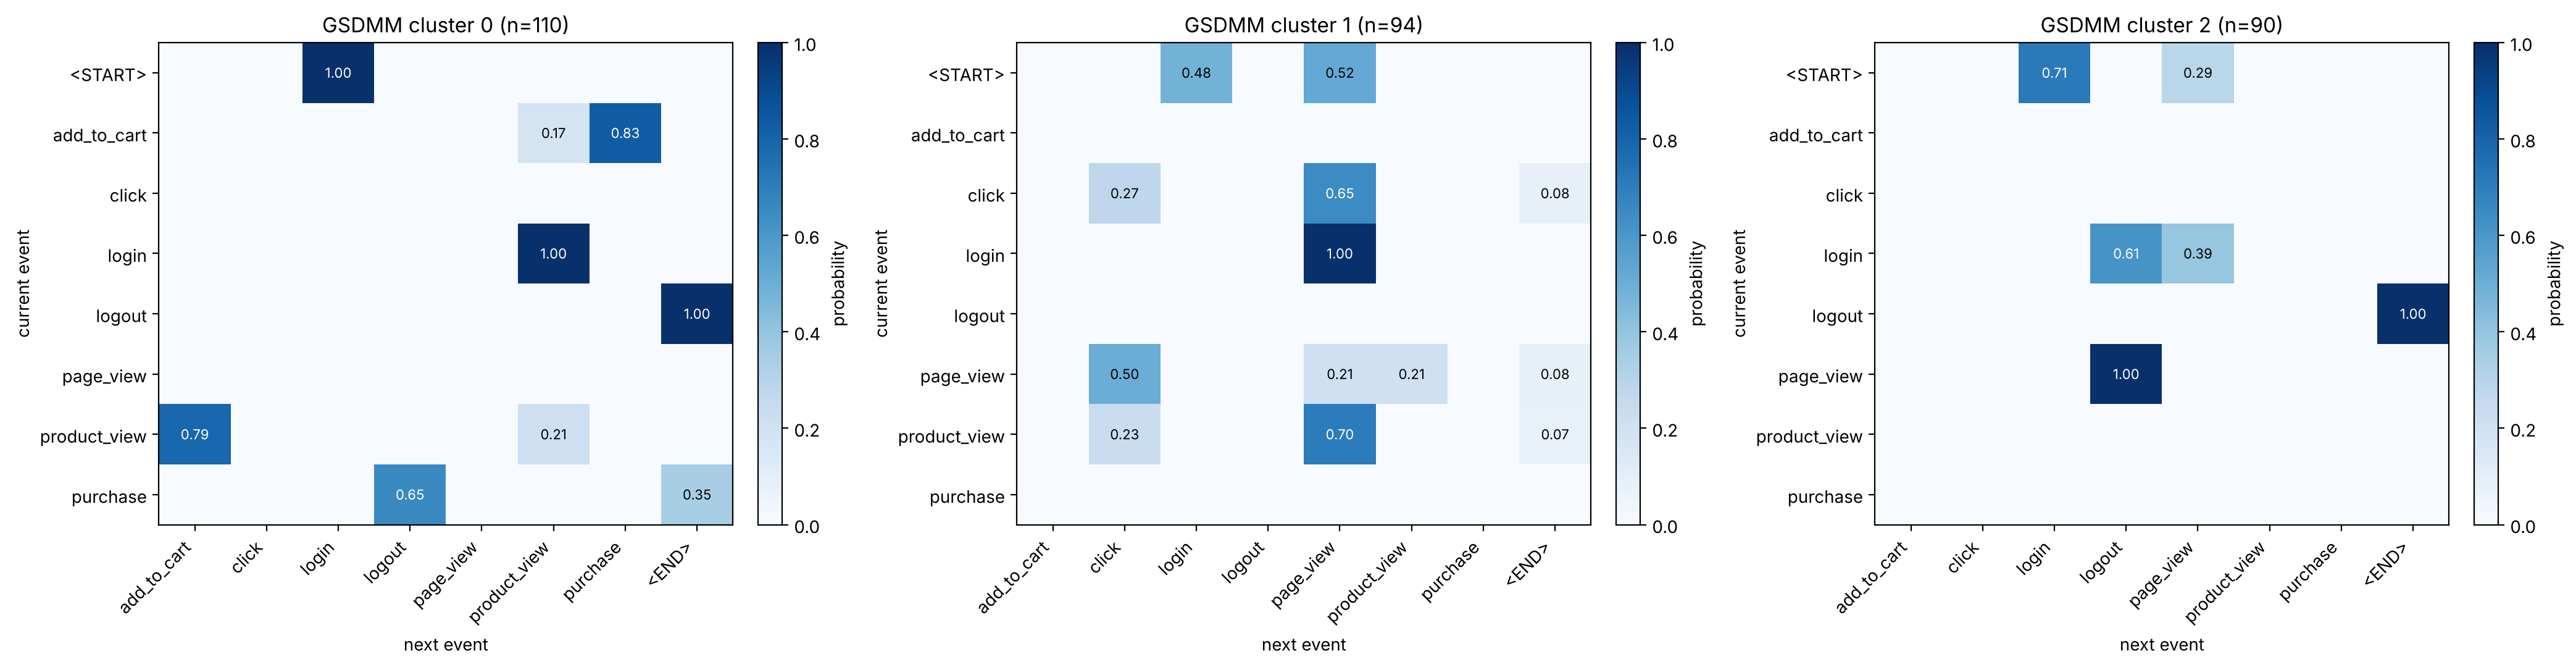

In [11]:
prof = sm_g.profile()
rows_ = [s for s in prof.states if s != END]; cols_ = [s for s in prof.states if s != START]
n_show = min(3, sm_g.n_clusters_found_)
fig, axes = plt.subplots(1, n_show, figsize=(7 * n_show, 5.5))
for c, ax in zip(range(n_show), np.atleast_1d(axes)):
    plot_transition_matrix(prof.transition_matrix(c), prof.states, title=f"GSDMM cluster {c} (n={int((sm_g.labels_ == c).sum())})",
                           ax=ax, vmax=1.0, rows=rows_, cols=cols_)
plt.tight_layout(); plt.show()

## 9. Scalability (fresh Markov-generated sessions, not bootstrapped duplicates)
Bootstrapping 5,000 sessions up to 100,000 creates exact duplicates, and an encoder that caches unique texts then looks far too cheap. So each N is a **fresh draw** from the K1 chains, and the table reports the **unique-text ratio** next to every time. Stage 2's spherical k-means is the reference.

**Caveat on the numbers:** if the encoder is the stand-in, the `embed` column measures hashing, not SBERT. Re-run with SBERT, and report CPU or GPU, and the one-off model load time (`ENCODER.load_seconds_`) separately.

,unique texts,render + terms (s),embed (s),k-means on embeddings (s),GSDMM 15 sweeps (s),Stage 2 k-gram + k-means (s)
N,,,,,,
500,40%,0.01,0.00,0.01,0.26,0.01
1000,34%,0.03,0.01,0.01,0.52,0.01
2000,30%,0.03,0.01,0.02,0.77,0.02
5000,25%,0.07,0.01,0.03,2.07,0.04
10000,23%,0.15,0.03,0.06,4.50,0.12
20000,20%,0.50,0.08,0.15,9.25,0.14


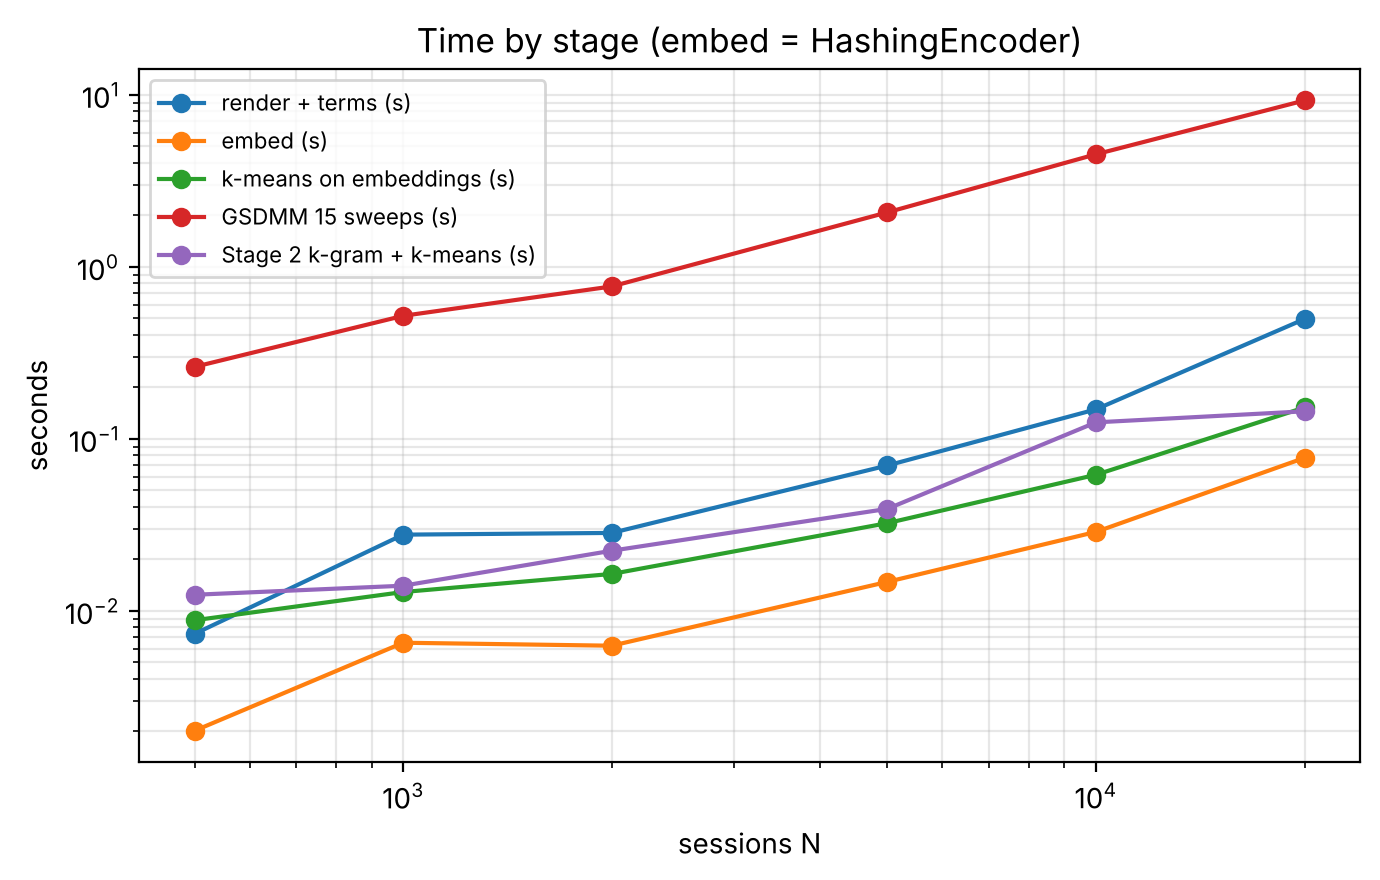

In [12]:
def fresh_sessions(n, seed):
    rng = np.random.default_rng(seed); names = list(CHAINS)
    return [walk(CHAINS[names[int(rng.integers(3))]], rng) for _ in range(n)]

rows = []
for n in (500, 1000, 2000, 5000, 10000, 20000):
    X = fresh_sessions(n, seed=n)
    sm = SemanticNLPModel(SessionRenderer("natural", rle=True), encoder=ENCODER)
    t0 = time.perf_counter(); sm.fit_texts(X); t_text = time.perf_counter() - t0
    t0 = time.perf_counter(); sm.fit_embeddings(); t_emb = time.perf_counter() - t0
    t0 = time.perf_counter(); sm.cluster(3, "sbert", random_state=0); t_km = time.perf_counter() - t0
    uniq = len(set(sm.texts)) / n
    t_gs = np.nan
    if n <= 20000:
        t0 = time.perf_counter(); sm.cluster(10, "gsdmm", random_state=0, n_iter=15); t_gs = time.perf_counter() - t0
    t0 = time.perf_counter(); tm = TransitionModel(k=2).fit_kgrams(X); tm.cluster(3, "kmeans", random_state=0); t_s2 = time.perf_counter() - t0
    rows.append({"N": n, "unique texts": f"{uniq:.0%}", "render + terms (s)": t_text, "embed (s)": t_emb,
                 "k-means on embeddings (s)": t_km, "GSDMM 15 sweeps (s)": t_gs, "Stage 2 k-gram + k-means (s)": t_s2})
scal = pd.DataFrame(rows).set_index("N")
display(scal.round(2))

fig, ax = plt.subplots(figsize=(7, 4.5))
for col in scal.columns[1:]:
    ax.loglog(scal.index, scal[col], marker="o", label=col)
ax.set_xlabel("sessions N"); ax.set_ylabel("seconds"); ax.set_title(f"Time by stage (embed = {ENCODER_NAME.split(' ')[0]})")
ax.grid(alpha=.3, which="both"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

GSDMM is a Python loop over sessions (about linear in N but with a large constant), which is why the benchmark fits it on a **sample** and uses `predict()` for the rest. Embedding and k-means are linear in N; no N x N matrix exists anywhere in Stage 3.

## 10. Conclusions

**Scope of these numbers.** Synthetic controls only, and the `embed` rows come from the encoder named in section 1. In the saved copy that is the lexical **stand-in**, so nothing below says anything yet about real SBERT. What the run does establish is the mechanics, the limits of every bag-of-words representation, and which comparisons are fair.

1. **The pipeline works end to end.** All four methods cluster, describe, predict and profile. The descriptors are readable without looking at the labels: GSDMM cluster 0 is `login > product_view`, `add_to_cart`, `purchase` (the buyers), cluster 1 is the `click`/`page_view` loop, cluster 2 ends in `logout` after 2 events. The Markov profile agrees with the empirical purchase share in every cluster (section 8).
2. **Order has to be put in by hand.** Unigram terms and an embedding of a bag-of-words encoder score ARI 0.00 on K2 (forward vs reversed funnel). Bigram terms fix it for LDA (1.00) and partly for GSDMM (0.70, because GSDMM splits into 6 clusters instead of 2). With bigram terms these models are close relatives of Stage 2's k=2 k-grams, which also scores 1.00.
3. **No semantic method beat Stage 2 on K1.** Stage 2 k=1 reaches 0.81, k=2 0.68 ± 0.14; LDA 0.61, embeddings 0.54-0.57, GSDMM 0.45-0.53. Differences between neighbouring rows are within about one SD, so only the gap between k=1 and the embedding/GSDMM rows is worth discussing, and it comes with the caveat that these controls use only 7 event types.
4. **K5 (synonyms) is the open question.** Every method that matches exact words scores low (0.10-0.44). The reference printed under the table, ARI 0.57 for a perfect clustering that cannot tell that `login` = `sign_in`, shows that GSDMM's 0.44 is *below* what pure vocabulary splitting can reach, so it is not evidence of robustness. Only an encoder that knows word meaning can score above 0.57. **That is the one result this notebook cannot give without SBERT, and the experiment that decides whether Stage 3 earns its place.**
5. **Windowing is real, but it is not a semantic advantage.** With the same last-2 window, Stage 2 k-grams (1.00) match the best semantic rows (1.00); on the full session they fall to 0.03, embeddings to 0.45 and GSDMM to 0.55. So the dilution effect (Experiment 4) is demonstrated, but it applies to every representation, and it only helps when the question is about the end of the session. Windows of 3-5 already bring the prefix back (0.51-0.65).
6. **GSDMM and HDBSCAN choose their own number of clusters**, and that is a source of ARI differences by itself. GSDMM found 5-9 clusters for 3 groups; HDBSCAN found 6-19 depending on `min_cluster_size` (1% vs 5% of N). Always report `k̂` next to the score.
7. **Cost.** Everything in Stage 3 is about linear in N and no N x N matrix is built. GSDMM is the slowest stage (about 0.5 s per 1,000 sessions for 15 sweeps here, 9.6 s at N = 20,000), still far cheaper than Stage 1's pairwise matrix. Encoding cost for real SBERT, the one-off model load and CPU vs GPU are not measured here.
8. **Next: run the notebook where SBERT can be downloaded** and read three things: the K5 row against the 0.57 ceiling, `embed natural` against `embed symbols` (any gap is due to word meaning, since the stand-in shows none), and `embed` against the stand-in rows (does pre-trained semantics beat a same-dimension lexical encoder?). Then run `semantic_realdata.ipynb`.